# TronSentinel · Semana 5
## Workshops: Simulación de escenarios críticos y Sensibilidad de hiperparámetros

**Autores:** Madheline Katerine Torres Hallo y Carlos Vladimir Ramírez Espinoza · Proyecto Integrador en IA (UEES)

**Caso:** priorizar wallets TRON para revisión humana según su similitud con wallets que luego fueron incluidas en la blacklist de Tether. Un **falso negativo** (no detectar una wallet riesgosa) puede costar fondos de forma irreversible; un **falso positivo** genera una revisión innecesaria y un posible daño reputacional. La métrica principal es el **recall de la clase riesgosa**, acompañada de FPR, precisión y PR-AUC.

| Parte | Qué hacemos | Concepto |
|---|---|---|
| 0 | Baseline y evaluación con incertidumbre | Métricas básicas, IC, validación cruzada agrupada |
| Workshop 1 | Ruido, faltantes, prevalencia, cambio de distribución, variable caída y **fraccionamiento adversarial** | Validación en contextos simulados |
| Workshop 2 | Optuna, importancia, slice, partial dependence e interacciones | Sensibilidad de hiperparámetros |
| Cierre | Comparación final y prueba de estrés del modelo optimizado | Validación en contextos reales |

**Reglas de gobernanza que respetamos (diferencias con el notebook de la clase):**
- El modelo evaluado en el Workshop 1 es el **artefacto desplegado** `tronsentinel-onchain-riskset-v0.6.1`, no un modelo reentrenado.
- Los escenarios se aplican sobre el **holdout externo** (286 filas). Ese conjunto ya se abrió una vez para aprobar el modelo; aquí lo usamos **solo para reportar**, sin cambiar el modelo ni el umbral.
- La búsqueda de hiperparámetros usa **validación cruzada agrupada por `matchedCaseId` solo sobre train**. Validación y holdout se consultan una vez, al final.

## 0. Preparación y baseline

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.evaluate import classification_metrics, grouped_bootstrap_difference, ppv_at_prevalence, wilson_interval
from src.model import load_model, predict_proba, threshold
from src.train import DEPLOYED_PARAMS, SEED, BalancedGradientBoosting

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
FIG = ROOT / "results" / "figures" / "optimizacion"
MET = ROOT / "results" / "metrics"
FIG.mkdir(parents=True, exist_ok=True)
MET.mkdir(parents=True, exist_ok=True)

META = ["cohortId", "matchedCaseId", "address", "indexAtUtc", "datasetSplit", "target"]
dev = pd.read_csv(ROOT / "data/processed/development_dataset_v6.csv")
ext = pd.read_csv(ROOT / "data/processed/external_holdout_v6.csv")
FEATURES = [c for c in dev.columns if c not in META]
train, val = dev[dev.datasetSplit == "train"], dev[dev.datasetSplit == "validation"]
X_train, y_train, g_train = train[FEATURES], train.target.values, train.matchedCaseId.values
X_val, y_val = val[FEATURES], val.target.values
X_ext, y_ext, g_ext = ext[FEATURES], ext.target.values, ext.matchedCaseId.values

modelo = load_model(ROOT / "models/model_v0.6.1.json")
UMBRAL_MODELO = threshold(modelo)
print(f"Variables: {len(FEATURES)} | train: {len(train)} ({y_train.sum()} riesgosas) | validación: {len(val)} | holdout externo: {len(ext)} ({y_ext.sum()} riesgosas)")
print(f"Prevalencia en el holdout (case-control): {y_ext.mean():.3f} | umbral congelado: {UMBRAL_MODELO:.4f}")

Variables: 38 | train: 1294 (280 riesgosas) | validación: 278 | holdout externo: 286 (99 riesgosas)
Prevalencia en el holdout (case-control): 0.346 | umbral congelado: 0.4289


In [2]:
def evaluar(prob, y, umbral=UMBRAL_MODELO):
    """Métricas de la clase riesgosa en el umbral indicado."""
    return classification_metrics(y, prob, umbral)


dummy = DummyClassifier(strategy="stratified", random_state=SEED).fit(X_train, y_train)
logistica = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")).fit(np.log1p(X_train.clip(lower=0)), y_train)
p_dummy = dummy.predict_proba(X_ext)[:, 1]
p_log = logistica.predict_proba(np.log1p(X_ext.clip(lower=0)))[:, 1]
p_modelo = predict_proba(modelo, X_ext)

tabla = pd.DataFrame({
    "dummy (estratificado)": evaluar(p_dummy, y_ext, 0.5),
    "regresión logística": evaluar(p_log, y_ext, 0.5),
    "TronSentinel v0.6.1": evaluar(p_modelo, y_ext),
}).T
tabla.round(3)

,accuracy,recall,precision,f1,fpr,auc,auc_pr
dummy (estratificado),0.580,0.182,0.316,0.231,0.209,0.487,0.341
regresión logística,0.853,0.899,0.736,0.809,0.171,0.956,0.913
TronSentinel v0.6.1,0.906,0.798,0.919,0.854,0.037,0.962,0.929


In [3]:
# Intervalos de confianza: Wilson para proporciones y validación cruzada agrupada sobre train
pred = (p_modelo >= UMBRAL_MODELO).astype(int)
tp, pos = int(((pred == 1) & (y_ext == 1)).sum()), int(y_ext.sum())
fp, neg = int(((pred == 1) & (y_ext == 0)).sum()), int((y_ext == 0).sum())
r = wilson_interval(tp, pos)
f = wilson_interval(fp, neg)
print(f"Recall = {r[0]:.3f}  IC95% [{r[1]:.3f}, {r[2]:.3f}]  ({tp}/{pos})")
print(f"FPR    = {f[0]:.3f}  IC95% [{f[1]:.3f}, {f[2]:.3f}]  ({fp}/{neg})")

cv = GroupKFold(n_splits=5)
scores = cross_val_score(BalancedGradientBoosting(**DEPLOYED_PARAMS), X_train, y_train, groups=g_train,
                         cv=cv, scoring="average_precision")
rng = np.random.default_rng(SEED)
boot = [rng.choice(scores, len(scores)).mean() for _ in range(2000)]
bajo, alto = np.percentile(boot, [2.5, 97.5])
print(f"PR-AUC (GroupKFold 5, train) = {scores.mean():.3f} ± {scores.std():.3f}   IC95% = [{bajo:.3f}, {alto:.3f}]")

Recall = 0.798  IC95% [0.708, 0.865]  (79/99)
FPR    = 0.037  IC95% [0.018, 0.075]  (7/187)


PR-AUC (GroupKFold 5, train) = 0.910 ± 0.011   IC95% = [0.899, 0.919]


---
# Workshop 1 · Simulación de escenarios críticos

**Pregunta guía:** ¿hasta qué nivel de perturbación el modelo desplegado sigue siendo útil, y qué debe hacer el sistema cuando deja de serlo?

**Criterio de aceptación definido ANTES de ejecutar:** caída máxima de **0,10** en recall respecto del holdout sin perturbar.
*Justificación:* con 99 casos positivos, el IC 95 % del recall base tiene un semiancho de ~0,08; caídas menores no se distinguen del ruido de muestreo. Para la precisión no fijamos un umbral único porque depende de la prevalencia (escenario C).

**Método:** cada perturbación se aplica al holdout externo y se repite con 10 semillas; se reportan promedios.

In [4]:
UMBRAL_CAIDA = 0.10
MEDIANA_TRAIN = X_train.median()
COLUMNAS_PROPORCION = [c for c in FEATURES if any(k in c for k in ("Ratio", "Share", "Hhi"))]


def evaluar_perturbado(perturbar, n_rep=10, mod=modelo, X=X_ext, y=y_ext):
    """Aplica perturbar(X, y, rng) -> (X2, y2) n_rep veces y promedia las métricas."""
    res = []
    for i in range(n_rep):
        X2, y2 = perturbar(X.copy(), y.copy(), np.random.default_rng(SEED + i))
        res.append(evaluar(predict_proba(mod, X2), y2))
    return pd.DataFrame(res).mean().to_dict()


resumen = [{"escenario": "Base", "nivel": "sin perturbar", **evaluar(p_modelo, y_ext)}]

### Escenario A · Error de medición (ruido multiplicativo)
Las variables on-chain son montos, conteos y tiempos con colas muy largas, así que un ruido aditivo de σ × std las destruiría. Simulamos un **error proporcional**: cada valor se multiplica por exp(N(0, σ)). Las proporciones se recortan a [0, 1].

In [5]:
def ruido(s):
    def f(X, y, rng):
        X = X * np.exp(rng.normal(0, s, X.shape))
        X[COLUMNAS_PROPORCION] = X[COLUMNAS_PROPORCION].clip(0, 1)
        return X, y
    return f


for s in [0.1, 0.25, 0.5, 1.0]:
    resumen.append({"escenario": "Ruido", "nivel": f"σ={s}", **evaluar_perturbado(ruido(s))})
pd.DataFrame([r for r in resumen if r["escenario"] == "Ruido"]).round(3)

,escenario,nivel,accuracy,recall,precision,f1,fpr,auc,auc_pr
0,Ruido,σ=0.1,0.898,0.790,0.904,0.843,0.044,0.961,0.928
1,Ruido,σ=0.25,0.896,0.796,0.892,0.841,0.051,0.957,0.924
2,Ruido,σ=0.5,0.888,0.782,0.882,0.829,0.056,0.949,0.911
3,Ruido,σ=1.0,0.868,0.729,0.869,0.793,0.058,0.936,0.889


### Escenario B · Datos faltantes
Una fracción *p* de los valores se pierde y se imputa con la mediana de entrenamiento. *En producción esto no ocurre así:* una historia incompleta se marca `NOT_SCORABLE`. El escenario mide qué pasaría si esa salvaguarda fallara.

In [6]:
def faltantes(p):
    def f(X, y, rng):
        mask = rng.random(X.shape) < p
        relleno = np.broadcast_to(MEDIANA_TRAIN.values, X.shape)
        arr = X.values.copy()
        arr[mask] = relleno[mask]
        return pd.DataFrame(arr, columns=X.columns, index=X.index), y
    return f


for p in [0.1, 0.3, 0.5]:
    resumen.append({"escenario": "Faltantes", "nivel": f"{int(p * 100)}%", **evaluar_perturbado(faltantes(p))})
pd.DataFrame([r for r in resumen if r["escenario"] == "Faltantes"]).round(3)

,escenario,nivel,accuracy,recall,precision,f1,fpr,auc,auc_pr
0,Faltantes,10%,0.854,0.640,0.912,0.752,0.033,0.941,0.898
1,Faltantes,30%,0.772,0.391,0.889,0.541,0.026,0.891,0.828
2,Faltantes,50%,0.712,0.194,0.880,0.316,0.014,0.840,0.748


### Escenario C · Prevalencia realista (desbalance extremo)
El holdout tiene 34,6 % de wallets riesgosas por diseño case-control. Replicamos controles (con reemplazo) hasta la prevalencia objetivo. El modelo no cambia; solo cambia el mundo donde lo usamos.

In [7]:
def prevalencia(prev):
    def f(X, y, rng):
        pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
        n_neg = int(round(len(pos) * (1 - prev) / prev))
        idx = np.concatenate([pos, rng.choice(neg, n_neg, replace=True)])
        return X.iloc[idx], y[idx]
    return f


for prev in [0.2, 0.1, 0.05, 0.01]:
    resumen.append({"escenario": "Prevalencia", "nivel": f"{prev:.0%} riesgosas", **evaluar_perturbado(prevalencia(prev))})
pd.DataFrame([r for r in resumen if r["escenario"] == "Prevalencia"]).round(3)

,escenario,nivel,accuracy,recall,precision,f1,fpr,auc,auc_pr
0,Prevalencia,20% riesgosas,0.929,0.798,0.840,0.818,0.039,0.961,0.871
1,Prevalencia,10% riesgosas,0.947,0.798,0.709,0.750,0.037,0.962,0.790
2,Prevalencia,5% riesgosas,0.955,0.798,0.532,0.638,0.037,0.962,0.683
3,Prevalencia,1% riesgosas,0.961,0.798,0.178,0.291,0.037,0.962,0.418


### Escenario D · Cambio de distribución (volumen)
Entrenamos con la configuración desplegada **solo con wallets de bajo volumen** (monto total ≤ mediana de train) y evaluamos en el holdout por separado sobre wallets de bajo y de alto volumen. Es como desplegar el modelo en una población de usuarios distinta. El umbral se elige en validación (bajo volumen) con FPR ≤ 5 %.

In [8]:
def umbral_por_fpr(prob, y, max_fpr=0.05):
    """Umbral más bajo cuyo FPR en (prob, y) no supera max_fpr."""
    for t in np.unique(prob):
        if ((prob >= t) & (y == 0)).sum() / max((y == 0).sum(), 1) <= max_fpr:
            return float(t)
    return 1.0


corte = X_train["totalAmount"].median()
bajo_tr = X_train["totalAmount"] <= corte
mod_shift = BalancedGradientBoosting(**DEPLOYED_PARAMS).fit(X_train[bajo_tr], y_train[bajo_tr])
bajo_val = X_val["totalAmount"] <= corte
t_shift = umbral_por_fpr(mod_shift.predict_proba(X_val[bajo_val])[:, 1], y_val[bajo_val])
bajo_ext = (X_ext["totalAmount"] <= corte).values
ref = evaluar(mod_shift.predict_proba(X_ext[bajo_ext])[:, 1], y_ext[bajo_ext], t_shift)
shift = evaluar(mod_shift.predict_proba(X_ext[~bajo_ext])[:, 1], y_ext[~bajo_ext], t_shift)
resumen.append({"escenario": "Cambio de distribución", "nivel": "bajo volumen (ref.)", **ref})
resumen.append({"escenario": "Cambio de distribución", "nivel": "alto volumen", **shift})
print(f"Corte de volumen: {corte:,.0f} USDT | train bajo volumen: {bajo_tr.sum()} filas ({y_train[bajo_tr].sum()} riesgosas)")
print(f"Holdout bajo volumen: {bajo_ext.sum()} ({y_ext[bajo_ext].sum()} riesgosas) | alto: {(~bajo_ext).sum()} ({y_ext[~bajo_ext].sum()} riesgosas)")
pd.DataFrame([ref, shift], index=["bajo volumen (ref.)", "alto volumen"]).round(3)

Corte de volumen: 151,065 USDT | train bajo volumen: 647 filas (78 riesgosas)
Holdout bajo volumen: 150 (34 riesgosas) | alto: 136 (65 riesgosas)


,accuracy,recall,precision,f1,fpr,auc,auc_pr
bajo volumen (ref.),0.867,0.735,0.694,0.714,0.095,0.939,0.838
alto volumen,0.860,0.954,0.795,0.867,0.225,0.960,0.960


### Escenario E · Una variable clave deja de llegar
Tomamos las 3 variables más importantes del modelo desplegado (por frecuencia y ganancia de sus stumps) y simulamos que llegan con un valor constante: la mediana de entrenamiento.

In [9]:
importancia = (pd.Series([s["feature"] for s in modelo["stumps"]]).value_counts())
ganancia = pd.Series({f: sum(abs(s["rightValue"] - s["leftValue"]) for s in modelo["stumps"] if s["feature"] == f)
                      for f in importancia.index}).sort_values(ascending=False)
top3 = list(ganancia.index[:3])
print("Variables más importantes (ganancia acumulada):", top3)


def variable_caida(cols):
    def f(X, y, rng):
        for c in cols:
            X[c] = MEDIANA_TRAIN[c]
        return X, y
    return f


for c in top3:
    resumen.append({"escenario": "Variable caída", "nivel": c, **evaluar_perturbado(variable_caida([c]), n_rep=1)})
resumen.append({"escenario": "Variable caída", "nivel": "las 3 juntas", **evaluar_perturbado(variable_caida(top3), n_rep=1)})
pd.DataFrame([r for r in resumen if r["escenario"] == "Variable caída"]).round(3)

Variables más importantes (ganancia acumulada): ['daysSinceLastTransfer', 'meanAmount', 'repeatedCounterpartyRatio']


,escenario,nivel,accuracy,recall,precision,f1,fpr,auc,auc_pr
0,Variable caída,daysSinceLastTransfer,0.664,0.030,1.000,0.059,0.000,0.881,0.801
1,Variable caída,meanAmount,0.654,0.000,0.000,0.000,0.000,0.938,0.898
2,Variable caída,repeatedCounterpartyRatio,0.895,0.818,0.871,0.844,0.064,0.953,0.919
3,Variable caída,las 3 juntas,0.654,0.000,0.000,0.000,0.000,0.826,0.741


### Escenario F (propio) · Fraccionamiento adversarial (*structuring*)
Un actor que sabe que se le monitorea puede **dividir cada transferencia en *k* partes** para parecer menos riesgoso. Solo las wallets riesgosas cambian:
conteos × k, montos medio, máximo y desviación ÷ k, totales iguales, tiempos entre eventos ÷ k.
Mide la vulnerabilidad del modelo a una evasión simple y realista.

In [10]:
CONTEOS = ["transferCount", "transactionCount", "inboundCount", "outboundCount", "usdtTransferCount",
           "tusdTransferCount", "averageDailyTransfers", "selfTransferCount"]
MONTOS_UNITARIOS = ["meanAmount", "maxAmount", "amountStd"]
TIEMPOS = ["meanInterEventSeconds", "interEventStdSeconds"]


def fraccionamiento(k):
    def f(X, y, rng):
        riesgosas = y == 1
        for c in [c for c in CONTEOS if c in X]:
            X.loc[riesgosas, c] = X.loc[riesgosas, c] * k
        for c in MONTOS_UNITARIOS:
            X.loc[riesgosas, c] = X.loc[riesgosas, c] / k
        for c in TIEMPOS:
            X.loc[riesgosas, c] = X.loc[riesgosas, c] / k
        return X, y
    return f


for k in [2, 5, 10]:
    resumen.append({"escenario": "Fraccionamiento", "nivel": f"k={k}", **evaluar_perturbado(fraccionamiento(k), n_rep=1)})
pd.DataFrame([r for r in resumen if r["escenario"] == "Fraccionamiento"]).round(3)

,escenario,nivel,accuracy,recall,precision,f1,fpr,auc,auc_pr
0,Fraccionamiento,k=2,0.878,0.717,0.910,0.802,0.037,0.948,0.899
1,Fraccionamiento,k=5,0.843,0.616,0.897,0.731,0.037,0.916,0.833
2,Fraccionamiento,k=10,0.769,0.404,0.851,0.548,0.037,0.884,0.756


### Tabla resumen y criterio de aceptación
En el escenario D la referencia es el subgrupo de bajo volumen, no la línea base, porque el modelo es otro.

In [11]:
df = pd.DataFrame(resumen)
recall_base = df.loc[0, "recall"]
df["referencia"] = recall_base
ref_idx = df["nivel"] == "bajo volumen (ref.)"
df.loc[df["escenario"] == "Cambio de distribución", "referencia"] = df.loc[ref_idx, "recall"].iloc[0]
df["caida_recall"] = df["referencia"] - df["recall"]
df["veredicto"] = np.where(df["caida_recall"] <= UMBRAL_CAIDA, "OK", "FALLA")
cols = ["escenario", "nivel", "recall", "fpr", "precision", "f1", "auc_pr", "accuracy", "caida_recall", "veredicto"]
df[cols].to_csv(MET / "s5_escenarios_criticos.csv", index=False)
df[cols].round(3)

,escenario,nivel,recall,fpr,precision,f1,auc_pr,accuracy,caida_recall,veredicto
0,Base,sin perturbar,0.798,0.037,0.919,0.854,0.929,0.906,0.000,OK
1,Ruido,σ=0.1,0.790,0.044,0.904,0.843,0.928,0.898,0.008,OK
2,Ruido,σ=0.25,0.796,0.051,0.892,0.841,0.924,0.896,0.002,OK
3,Ruido,σ=0.5,0.782,0.056,0.882,0.829,0.911,0.888,0.016,OK
4,Ruido,σ=1.0,0.729,0.058,0.869,0.793,0.889,0.868,0.069,OK
5,Faltantes,10%,0.640,0.033,0.912,0.752,0.898,0.854,0.158,FALLA
6,Faltantes,30%,0.391,0.026,0.889,0.541,0.828,0.772,0.407,FALLA
7,Faltantes,50%,0.194,0.014,0.880,0.316,0.748,0.712,0.604,FALLA
8,Prevalencia,20% riesgosas,0.798,0.039,0.840,0.818,0.871,0.929,0.000,OK
9,Prevalencia,10% riesgosas,0.798,0.037,0.709,0.750,0.790,0.947,0.000,OK


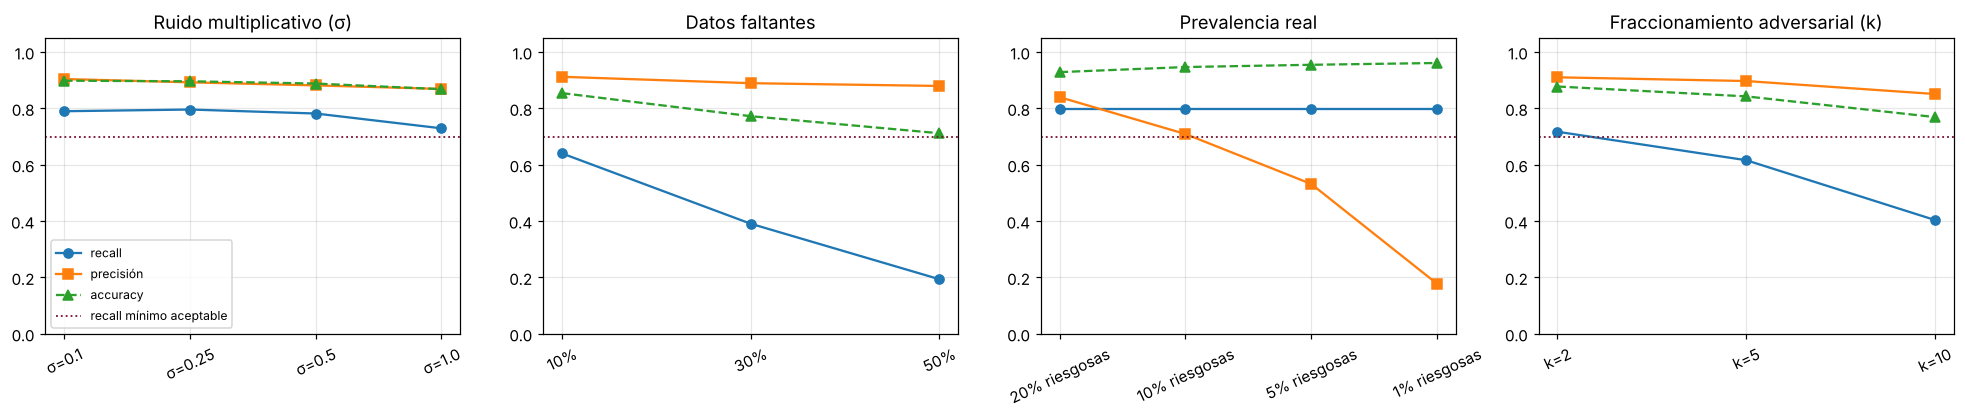

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.9))
for ax, esc, titulo in zip(axes, ["Ruido", "Faltantes", "Prevalencia", "Fraccionamiento"],
                           ["Ruido multiplicativo (σ)", "Datos faltantes", "Prevalencia real", "Fraccionamiento adversarial (k)"]):
    sub = df[df["escenario"] == esc]
    ax.plot(sub["nivel"], sub["recall"], "o-", label="recall")
    ax.plot(sub["nivel"], sub["precision"], "s-", label="precisión")
    ax.plot(sub["nivel"], sub["accuracy"], "^--", label="accuracy")
    ax.axhline(recall_base - UMBRAL_CAIDA, color="#7A1331", ls=":", lw=1.2, label="recall mínimo aceptable")
    ax.set_title(titulo); ax.set_ylim(0, 1.05); ax.tick_params(axis="x", rotation=25)
axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.savefig(FIG / "s5_escenarios_criticos.png", dpi=200, bbox_inches="tight"); plt.show()

**TAREA 1 · Respuestas**

**1. ¿Qué escenario degrada más el recall y cuál la precisión?**
El recall se degrada más cuando **falta una variable clave**: si `meanAmount` o `daysSinceLastTransfer` llegan constantes, el recall cae de 0,798 a 0,000 y 0,030. Le siguen los **datos faltantes** (30 %: 0,391; 50 %: 0,194) y el **fraccionamiento adversarial** (k=10: 0,404). La precisión se degrada sobre todo con la **prevalencia real**: pasa de 0,919 a 0,178 con 1 % de wallets riesgosas. El ruido de medición casi no afecta: con σ=1,0, el recall baja a 0,729 (caída de 0,069, dentro del criterio).

**2. ¿Por qué la *accuracy* engaña en el escenario C?**
Con 1 % de riesgosas, la accuracy **sube** de 0,906 a 0,961 mientras la precisión cae a 0,178 y la PR-AUC de 0,929 a 0,418. Con 99 % de wallets legítimas, decir "no riesgo" casi siempre acierta, así que la accuracy refleja a la clase mayoritaria y no la utilidad de las alertas. Por eso reportamos recall, FPR, precisión a una prevalencia declarada y PR-AUC.

**3. ¿Qué diferencia hay entre subgrupos en el escenario D y qué haríamos en producción?**
El modelo entrenado solo con wallets de bajo volumen obtiene recall 0,735 y FPR 9,5 % en su propio subgrupo. En alto volumen, el recall sube a 0,954, pero el **FPR se dispara a 22,5 %**: el modelo nunca vio wallets legítimas grandes y las confunde con riesgosas. El criterio de recall no lo detecta, pero el FPR supera el criterio de pausa de 10 % que definimos en el Workshop S4. En producción: (a) entrenar con toda la distribución de volumen, como el modelo desplegado; (b) monitorear el FPR por banda de volumen en la auditoría de subgrupos; (c) alertar por drift (PSI) si cambia la mezcla de volúmenes de las wallets consultadas.

**4. ¿Qué escenarios fallan y qué mitigación proponemos?**
- **Datos faltantes (≥ 10 %):** ya está mitigado por diseño, porque una historia incompleta devuelve `NOT_SCORABLE` y no se imputa. Agregaríamos una validación de completitud por variable antes de puntuar.
- **Variable caída:** muestra una **dependencia extrema de dos variables**. Además, `daysSinceLastTransfer` está sesgada por el diseño de muestreo (ciclo v7). Mitigación: monitoreo de integridad (alerta y pausa si una variable llega nula o constante); reentrenar con controles anclados en un instante aleatorio (*random-lookback*) y diversificar con variables no monetarias.
- **Fraccionamiento k ≥ 5:** es una vulnerabilidad adversarial. Mitigación: variables robustas a la fragmentación (contrapartes, montos totales por contraparte, ráfagas), entrenamiento con positivos fraccionados como aumento de datos y una advertencia explícita en el model card. El score nunca debe ser la única barrera.

**TAREA 2 · Escenario propio (fraccionamiento):** con k=2 el recall es 0,717 (caída de 0,081, en el límite del criterio); con k=5 cae a 0,616 y con k=10 a 0,404, ambos fuera del criterio. El FPR no cambia porque solo se alteran las wallets riesgosas, y la PR-AUC cae de 0,929 a 0,756. Un actor que divide sus transferencias en 5 partes evade casi uno de cada cuatro casos que hoy detectamos (0,182 / 0,798 = 23 %).

---
# Workshop 2 · Análisis de sensibilidad de hiperparámetros

**Pregunta guía:** ¿qué hiperparámetros merecen presupuesto de búsqueda y cuáles se pueden fijar?

**Método:** Optuna (TPE, 60 pruebas, semilla fija). Cada prueba se evalúa con **GroupKFold de 5 particiones por `matchedCaseId` solo sobre train**, optimizando **PR-AUC**: es la métrica adecuada con clases desbalanceadas y no depende del umbral. Incluimos `max_depth` de 1 a 4 aunque el scorer de producción solo acepta stumps (profundidad 1), para medir cuánto cuesta esa restricción.

In [13]:
import optuna
from optuna.visualization.matplotlib import (plot_contour, plot_optimization_history,
                                             plot_param_importances, plot_slice)
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import PartialDependenceDisplay

optuna.logging.set_verbosity(optuna.logging.WARNING)


def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 800),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 1, 4),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 60),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
    }
    scores = cross_val_score(BalancedGradientBoosting(**params), X_train, y_train, groups=g_train,
                             cv=cv, scoring="average_precision", n_jobs=2)
    trial.set_user_attr("std", float(scores.std()))
    return scores.mean()


study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study.enqueue_trial(DEPLOYED_PARAMS)   # la prueba 0 es la configuración desplegada (referencia)
study.optimize(objective, n_trials=60)
trials = study.trials_dataframe()
trials.to_csv(MET / "s5_optuna_trials.csv", index=False)
print("PR-AUC CV de la configuración desplegada:", round(study.trials[0].value, 4))
print("Mejor PR-AUC CV:", round(study.best_value, 4), "| parámetros:", study.best_params)
best_stump = max((t for t in study.trials if t.params["max_depth"] == 1), key=lambda t: t.value)
print("Mejor PR-AUC CV con stumps (desplegable):", round(best_stump.value, 4), "|", best_stump.params)
print("Rango de PR-AUC entre pruebas:", round(trials.value.min(), 4), "–", round(trials.value.max(), 4))

PR-AUC CV de la configuración desplegada: 0.9098
Mejor PR-AUC CV: 0.9225 | parámetros: {'n_estimators': 797, 'learning_rate': 0.005793610443073693, 'max_depth': 4, 'min_samples_leaf': 23, 'subsample': 0.5465085321089567}
Mejor PR-AUC CV con stumps (desplegable): 0.9124 | {'n_estimators': 141, 'learning_rate': 0.03797252233376349, 'max_depth': 1, 'min_samples_leaf': 55, 'subsample': 0.6293899908000085}
Rango de PR-AUC entre pruebas: 0.8955 – 0.9225


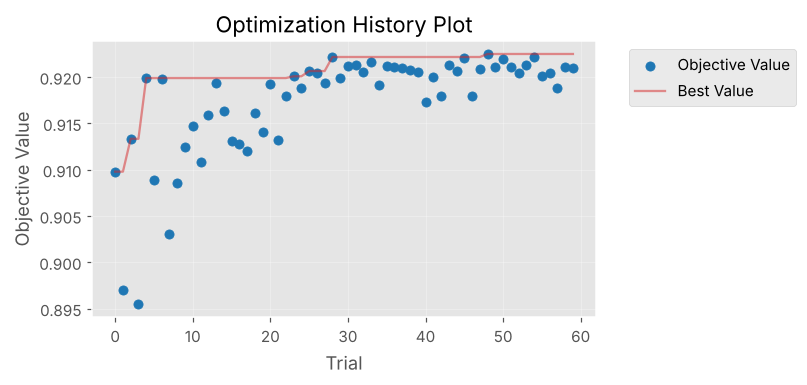

In [14]:
ax = plot_optimization_history(study)
ax.figure.set_size_inches(7.5, 3.6); plt.tight_layout()
plt.savefig(FIG / "s5_historial_optuna.png", dpi=200, bbox_inches="tight"); plt.show()

### 2.1 Importancia de hiperparámetros

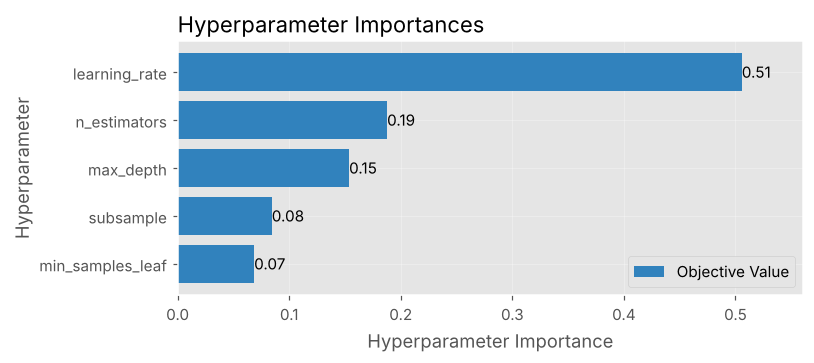

learning_rate       0.506
n_estimators        0.188
max_depth           0.154
subsample           0.084
min_samples_leaf    0.069
dtype: float64

In [15]:
importancias = optuna.importance.get_param_importances(study, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=42))
ax = plot_param_importances(study, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=42))
ax.figure.set_size_inches(7.5, 3.4); plt.tight_layout()
plt.savefig(FIG / "s5_importancia_hiperparametros.png", dpi=200, bbox_inches="tight"); plt.show()
pd.Series(importancias).rename("importancia (fANOVA)").to_csv(MET / "s5_importancia_hiperparametros.csv")
pd.Series(importancias).round(3)

### 2.2 Efecto individual: slice y partial dependence
Para el *partial dependence* ajustamos un Random Forest sustituto que predice la PR-AUC a partir de los hiperparámetros.

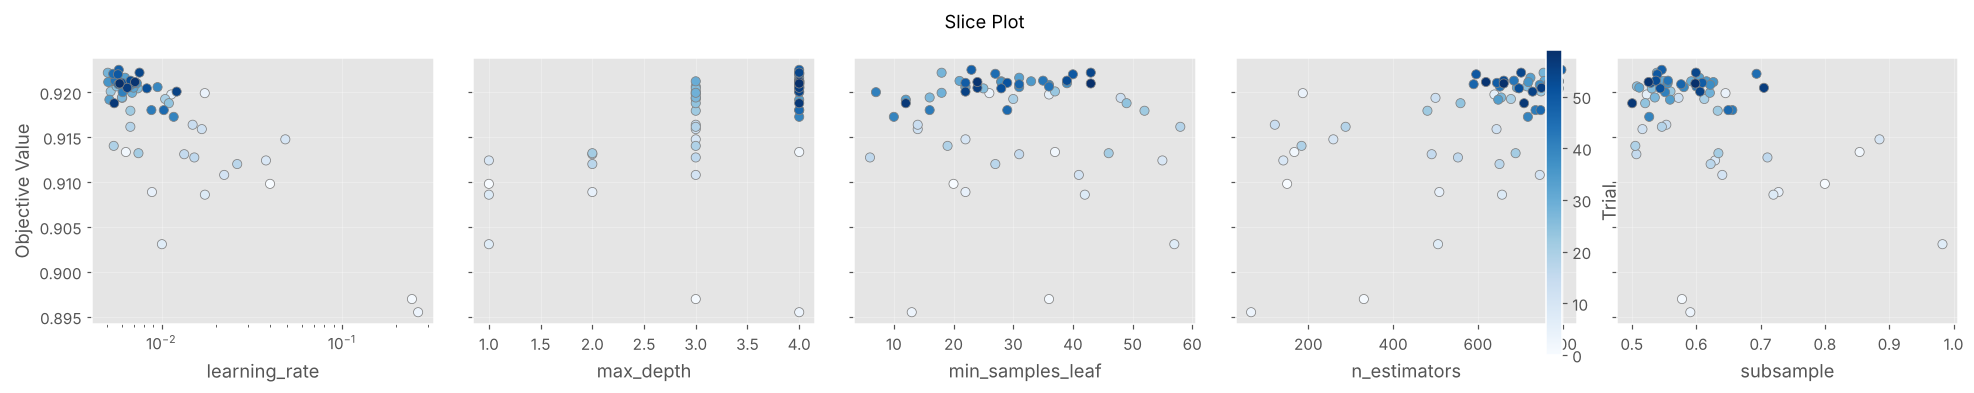

In [16]:
axs = plot_slice(study)
fig = np.ravel(axs)[0].figure
fig.set_size_inches(18, 3.6); plt.tight_layout()
plt.savefig(FIG / "s5_slice.png", dpi=200, bbox_inches="tight"); plt.show()

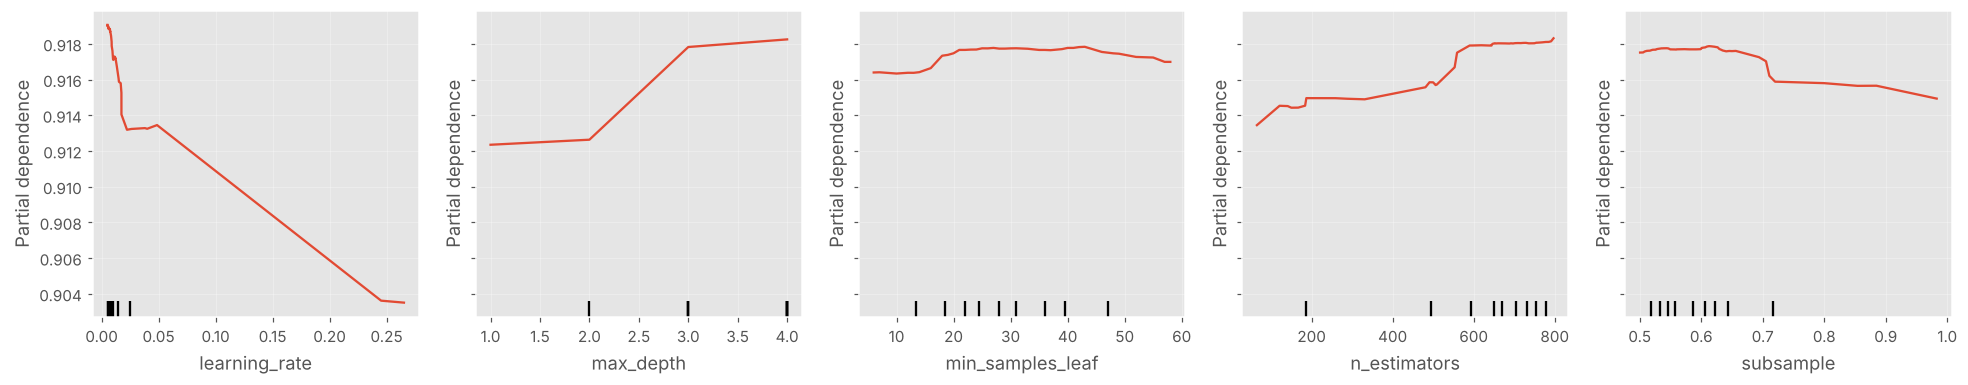

In [17]:
pcols = [c for c in trials.columns if c.startswith("params_")]
T = trials[pcols].astype(float)
T.columns = [c.replace("params_", "") for c in pcols]
sustituto = RandomForestRegressor(n_estimators=400, random_state=42).fit(T, trials["value"])
fig, axs = plt.subplots(1, len(T.columns), figsize=(18, 3.6), sharey=True)
PartialDependenceDisplay.from_estimator(sustituto, T, features=list(T.columns), ax=axs)
plt.tight_layout(); plt.savefig(FIG / "s5_partial_dependence.png", dpi=200, bbox_inches="tight"); plt.show()

### 2.3 Efectos de interacción
En boosting se espera una interacción fuerte entre la tasa de aprendizaje y el número de árboles (un *learning rate* bajo necesita más árboles). También miramos profundidad × número de árboles.

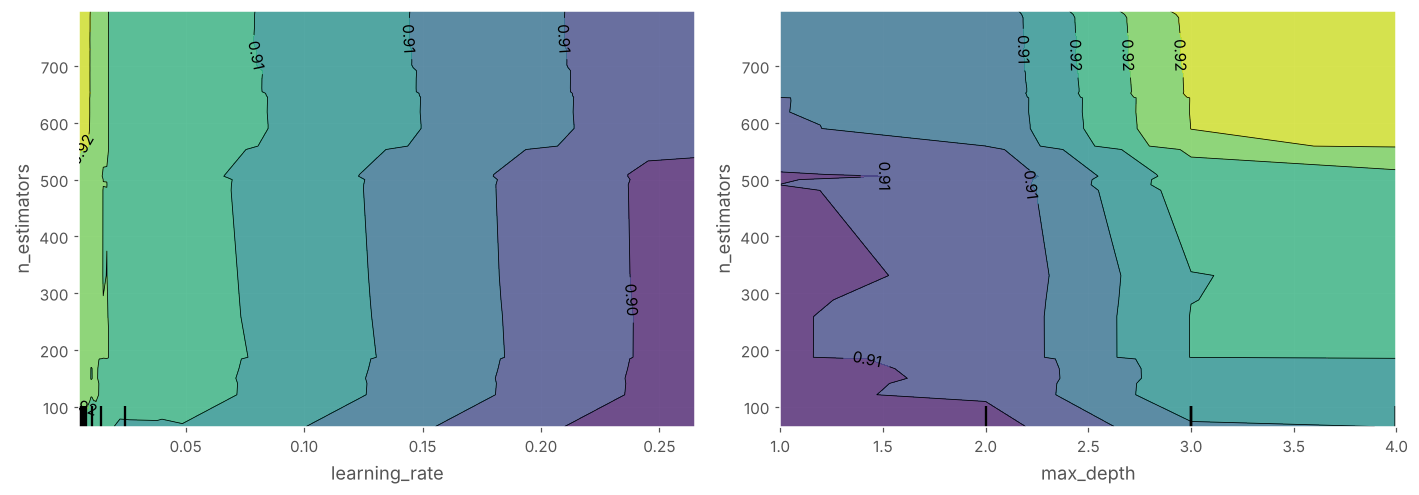

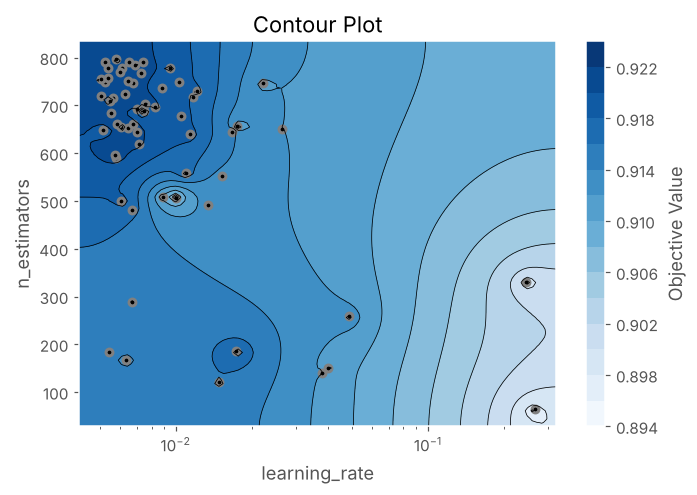

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, par in zip(axes, [("learning_rate", "n_estimators"), ("max_depth", "n_estimators")]):
    PartialDependenceDisplay.from_estimator(sustituto, T, features=[par], ax=ax, kind="average")
plt.tight_layout(); plt.savefig(FIG / "s5_interacciones_pdp2d.png", dpi=200, bbox_inches="tight"); plt.show()

ax = plot_contour(study, params=["learning_rate", "n_estimators"])
ax.figure.set_size_inches(6.5, 4.6); plt.tight_layout()
plt.savefig(FIG / "s5_contorno_lr_n.png", dpi=200, bbox_inches="tight"); plt.show()

**TAREA 3 · Respuestas**

**1. ¿Qué hiperparámetros importan y cuánto?**
Según fANOVA, importan **`learning_rate` (0,51)**, **`n_estimators` (0,19)** y **`max_depth` (0,15)**. `subsample` (0,08) y `min_samples_leaf` (0,07) casi no influyen: sus curvas de dependencia parcial varían menos de 0,002. La magnitud total es **pequeña**: las 60 pruebas quedan entre 0,896 y 0,923 de PR-AUC, un rango de 0,027, del orden de 2 a 3 veces la desviación estándar entre particiones de la configuración desplegada (0,011).

**2. ¿Hay interacción?**
- *learning_rate × n_estimators:* los contornos son casi verticales, así que la tasa de aprendizaje domina. Solo con tasas muy bajas (< 0,02) agregar árboles mejora el resultado: es la interacción típica del boosting, pero leve en este rango.
- *max_depth × n_estimators:* la interacción es **clara**. Una profundidad de 3–4 solo rinde con más de ~550 árboles; con stumps (profundidad 1), el número de árboles casi no cambia nada.

**3. ¿Qué ampliar y qué fijar?**
Ampliaríamos `n_estimators` por encima de 800 y `learning_rate` por debajo de 0,005, porque el mejor punto (797 árboles; 0,0058) quedó en el borde de la búsqueda, coherente con el early stopping de 600–900 iteraciones de la Semana 3. Fijaríamos `subsample` ≈ 0,6 y `min_samples_leaf` entre 20 y 40. `max_depth` queda en 1 por una restricción de despliegue: el scorer TypeScript solo ejecuta stumps. Usar más profundidad exige primero adaptar el exportador y el scorer.

**4. ¿Por qué 0,002 de diferencia no justifica elegir?**
La mejor configuración con stumps (0,9124) supera a la desplegada (0,9098) por 0,0026 en CV, una diferencia menor que la desviación entre particiones (0,011). En validación, la diferencia pareada por bootstrap agrupado es +0,0008 con IC [−0,006; 0,008], que incluye cero. No hay evidencia de mejora, así que cambiar sería ajustar ruido.

---
# Cierre · Comparación final y prueba de estrés del modelo optimizado
Entrenamos con todo train tres configuraciones: la desplegada, la mejor de Optuna sin restricciones y la mejor **desplegable** (stumps). Las comparamos en **validación** (no usada en la búsqueda) y en el **holdout externo** (consumido, solo informativo), con diferencias pareadas por bootstrap agrupado (2.000 repeticiones). El umbral de cada modelo se fija en validación con FPR ≤ 5 %, igual que en producción.

In [19]:
configs = {"desplegada (v0.6.1)": DEPLOYED_PARAMS, "Optuna libre": study.best_params, "Optuna stumps": best_stump.params}
modelos, prob_val, prob_ext, umbrales = {}, {}, {}, {}
for nombre, params in configs.items():
    m = BalancedGradientBoosting(**params).fit(X_train, y_train)
    modelos[nombre] = m
    prob_val[nombre] = m.predict_proba(X_val)[:, 1]
    prob_ext[nombre] = m.predict_proba(X_ext)[:, 1]
    umbrales[nombre] = umbral_por_fpr(prob_val[nombre], y_val)

filas = []
for nombre in configs:
    for conjunto, prob, y in [("validación", prob_val, y_val), ("holdout externo", prob_ext, y_ext)]:
        filas.append({"modelo": nombre, "conjunto": conjunto, **evaluar(prob[nombre], y, umbrales[nombre])})
final = pd.DataFrame(filas)
final.to_csv(MET / "s5_comparacion_final.csv", index=False)
final.pivot(index="modelo", columns="conjunto", values=["auc_pr", "auc", "recall", "fpr"]).round(3)

auc_pr                        auc             \
conjunto            holdout externo validación holdout externo validación   
modelo                                                                      
Optuna libre                  0.947      0.948           0.972      0.987   
Optuna stumps                 0.924      0.936           0.962      0.982   
desplegada (v0.6.1)           0.929      0.935           0.962      0.981   

                             recall                        fpr             
conjunto            holdout externo validación holdout externo validación  
modelo                                                                     
Optuna libre                  0.808      0.900           0.048      0.046  
Optuna stumps                 0.828      0.933           0.059      0.046  
desplegada (v0.6.1)           0.798      0.917           0.043      0.046

In [20]:
from sklearn.metrics import average_precision_score

g_val = val.matchedCaseId.values
diffs = []
for nombre in ["Optuna libre", "Optuna stumps"]:
    for conjunto, prob, y, g in [("validación", prob_val, y_val, g_val), ("holdout externo", prob_ext, y_ext, g_ext)]:
        d = grouped_bootstrap_difference(y, g, prob["desplegada (v0.6.1)"], prob[nombre], average_precision_score, 2000, SEED)
        diffs.append({"comparación": f"{nombre} − desplegada", "conjunto": conjunto, **d})
diffs = pd.DataFrame(diffs)
diffs.to_csv(MET / "s5_diferencias_pareadas.csv", index=False)
diffs.round(4)

,comparación,conjunto,point,lower95,upper95,includes_zero
0,Optuna libre − desplegada,validación,0.0135,-0.0061,0.0350,True
1,Optuna libre − desplegada,holdout externo,0.0178,0.0049,0.0348,False
2,Optuna stumps − desplegada,validación,0.0008,-0.0060,0.0077,True
3,Optuna stumps − desplegada,holdout externo,-0.0054,-0.0188,0.0031,True


In [21]:
# Prueba de estrés: desplegada vs. optimizados (cada uno en su propio umbral)
def evaluar_modelo_perturbado(m, t, perturbar, n_rep=10):
    res = []
    for i in range(n_rep):
        X2, y2 = perturbar(X_ext.copy(), y_ext.copy(), np.random.default_rng(SEED + i))
        res.append(evaluar(m.predict_proba(X2)[:, 1], y2, t))
    return pd.DataFrame(res).mean().to_dict()


filas = []
for nombre, m in modelos.items():
    for escenario, f in [("sin perturbar", lambda X, y, rng: (X, y)), ("ruido σ=0,5", ruido(0.5)),
                         ("faltantes 30%", faltantes(0.3)), ("prevalencia 5%", prevalencia(0.05)),
                         ("fraccionamiento k=5", fraccionamiento(5))]:
        n = 1 if escenario in ("sin perturbar", "fraccionamiento k=5") else 10
        filas.append({"modelo": nombre, "escenario": escenario, **evaluar_modelo_perturbado(m, umbrales[nombre], f, n)})
estres = pd.DataFrame(filas)
estres.to_csv(MET / "s5_estres_optimizado.csv", index=False)
estres.pivot(index="escenario", columns="modelo", values=["recall", "precision"]).round(3)

recall                                    \
modelo              Optuna libre Optuna stumps desplegada (v0.6.1)   
escenario                                                            
faltantes 30%              0.567         0.459               0.402   
fraccionamiento k=5        0.626         0.657               0.626   
prevalencia 5%             0.808         0.828               0.798   
ruido σ=0,5                0.812         0.804               0.784   
sin perturbar              0.808         0.828               0.798   

                       precision                                    
modelo              Optuna libre Optuna stumps desplegada (v0.6.1)  
escenario                                                           
faltantes 30%              0.881         0.869               0.887  
fraccionamiento k=5        0.873         0.855               0.886  
prevalencia 5%             0.475         0.432               0.497  
ruido σ=0,5                0.888         0.864               0.874  
sin perturbar              0.899         0.882               0.908

**Conclusiones del cierre**

- **Optuna libre** (profundidad 4, 797 árboles, tasa 0,006) mejora la PR-AUC en **+0,013 en validación, con IC [−0,006; 0,035] que incluye cero**: no hay mejora demostrada en el conjunto de confirmación limpio. En el holdout externo la diferencia es +0,018 [0,005; 0,035], pero ese conjunto ya estaba consumido y solo sirve como información. Además, esta configuración **no es desplegable** con el scorer actual. **Decisión:** no cambiamos el modelo. La registramos como hipótesis para el ciclo v8, que requiere un exportador de árboles profundos y una cohorte nueva.
- **Optuna stumps** (la versión desplegable) es equivalente a la desplegada: las diferencias pareadas incluyen cero en ambos conjuntos. La configuración actual ya está cerca del óptimo para stumps, y la optimización tiene **retornos decrecientes**, como en el ejemplo de la clase.
- **Estrés:** el modelo profundo es más robusto a los faltantes (recall 0,567 frente a 0,402 con 30 %), pero **los tres modelos caen igual ante el fraccionamiento** (~0,63 con k=5). Esa vulnerabilidad viene de las variables, no de los hiperparámetros, y se mitiga con datos y variables nuevas, no con más búsqueda.
- **Conclusión del Workshop S5:** el mayor riesgo de TronSentinel no está en el ajuste fino. Está en su **dependencia de dos variables**, en la **evasión por fraccionamiento** y en la **prevalencia real**. Esto refuerza las decisiones de la gobernanza: mantener v0.6.1 en SHADOW con revisión humana, devolver `NOT_SCORABLE` ante historias incompletas, monitorear la integridad de las variables y priorizar el rediseño de datos del ciclo v8.